# Example of the aitlas toolbox in the context of object detection in remote sensing images

Note: The IDTReeS dataset contains labels in shapefiles format.

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import IDTReeSDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects with bounding boxes

Total number of patches: 85


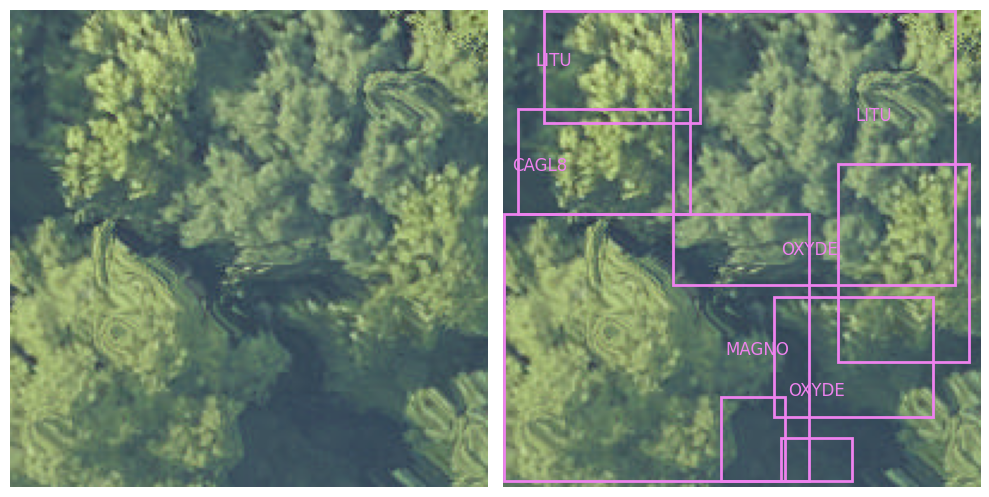

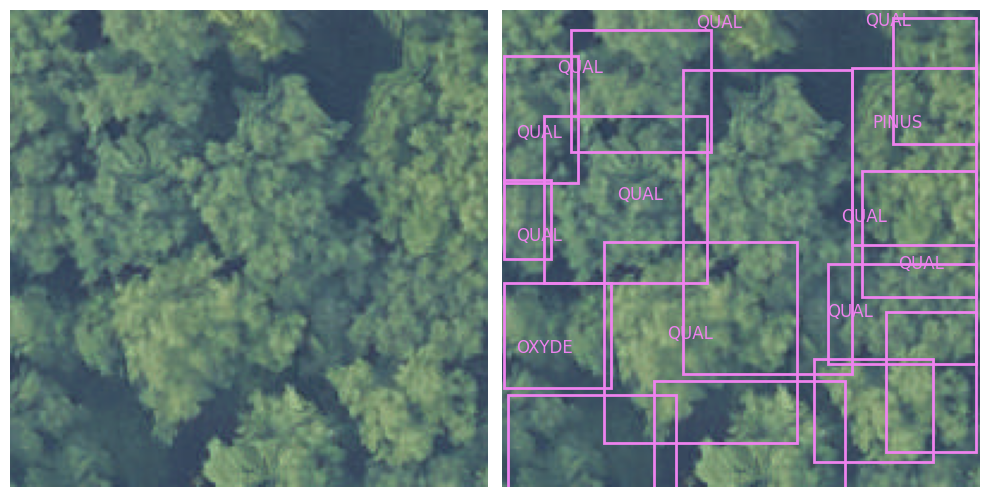

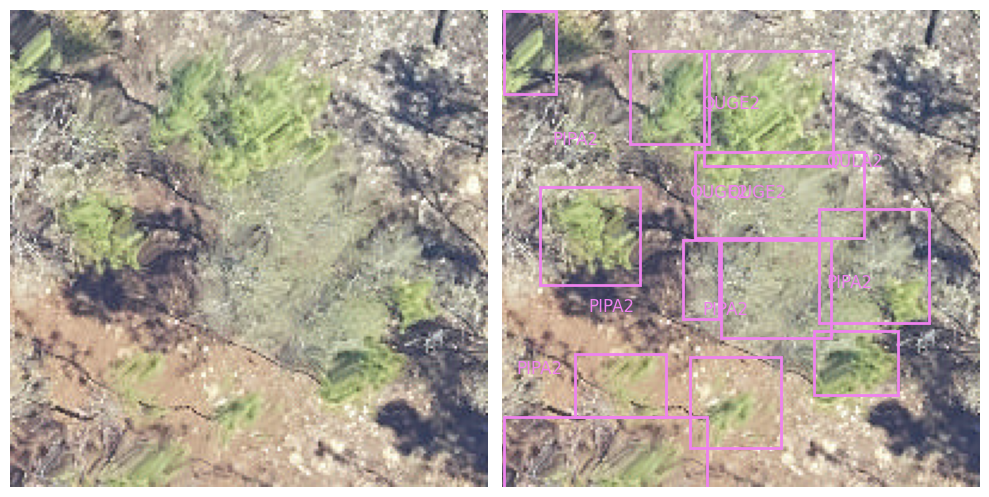

In [ ]:
dataset_config = {
    "data_dir": "./data/idtrees/IDTREES_competition_train_v2/train/RemoteSensing/RGB/",
    "annotation_dir": "./data/idtrees/IDTREES_competition_train_v2/train/ITC/",
    "csv_file": "./data/idtrees/IDTREES_competition_train_v2/train/Field/train_data.csv"
}
dataset = IDTReeSDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(80);

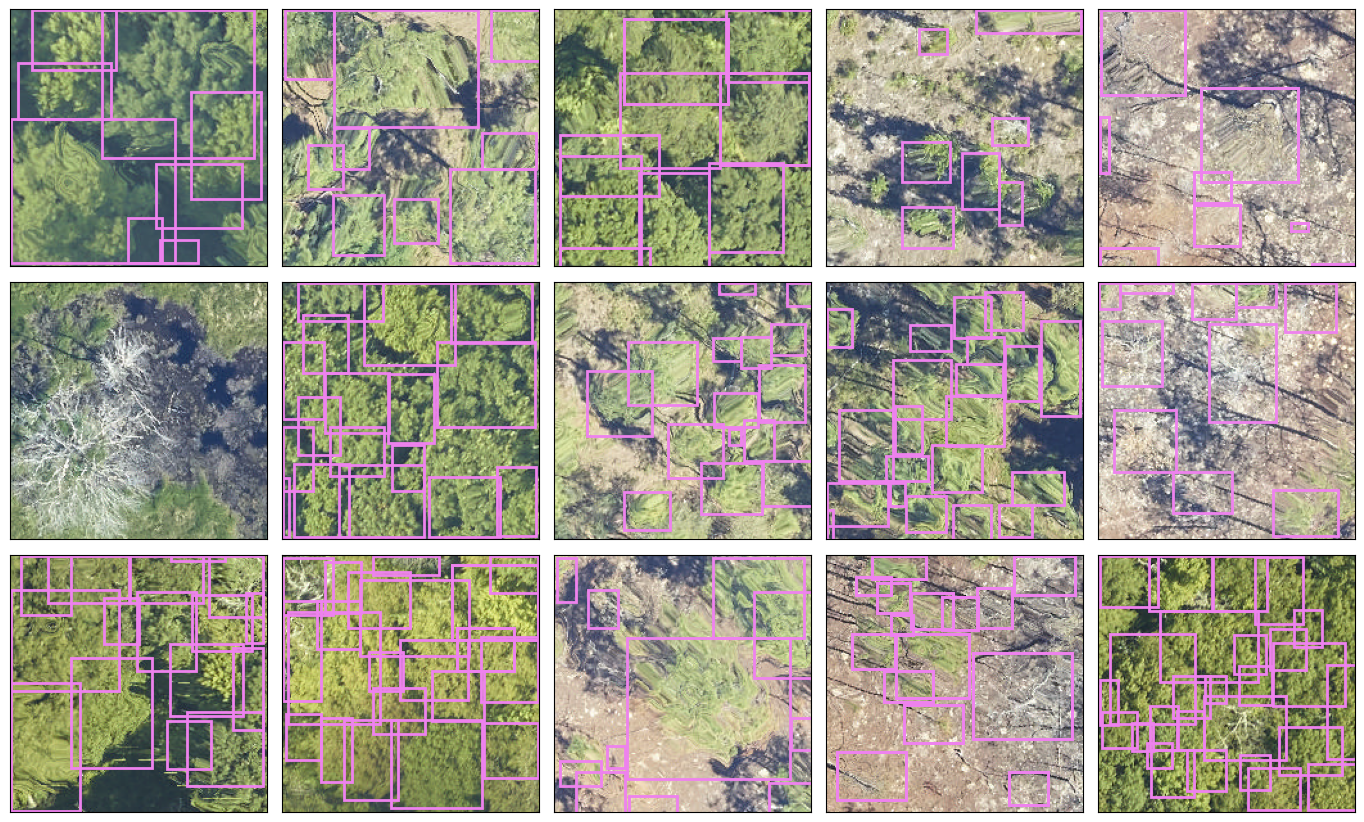

In [69]:
dataset.show_batch(15);

In [79]:
dataset.data_distribution_table()

,Label,Count
0,ACPE,8
1,ACRU,144
2,ACSA3,1
3,AMLA,50
4,BETUL,6
5,CAGL8,3
6,CATO6,1
7,FAGR,6
8,GOLA,1
9,LITU,17


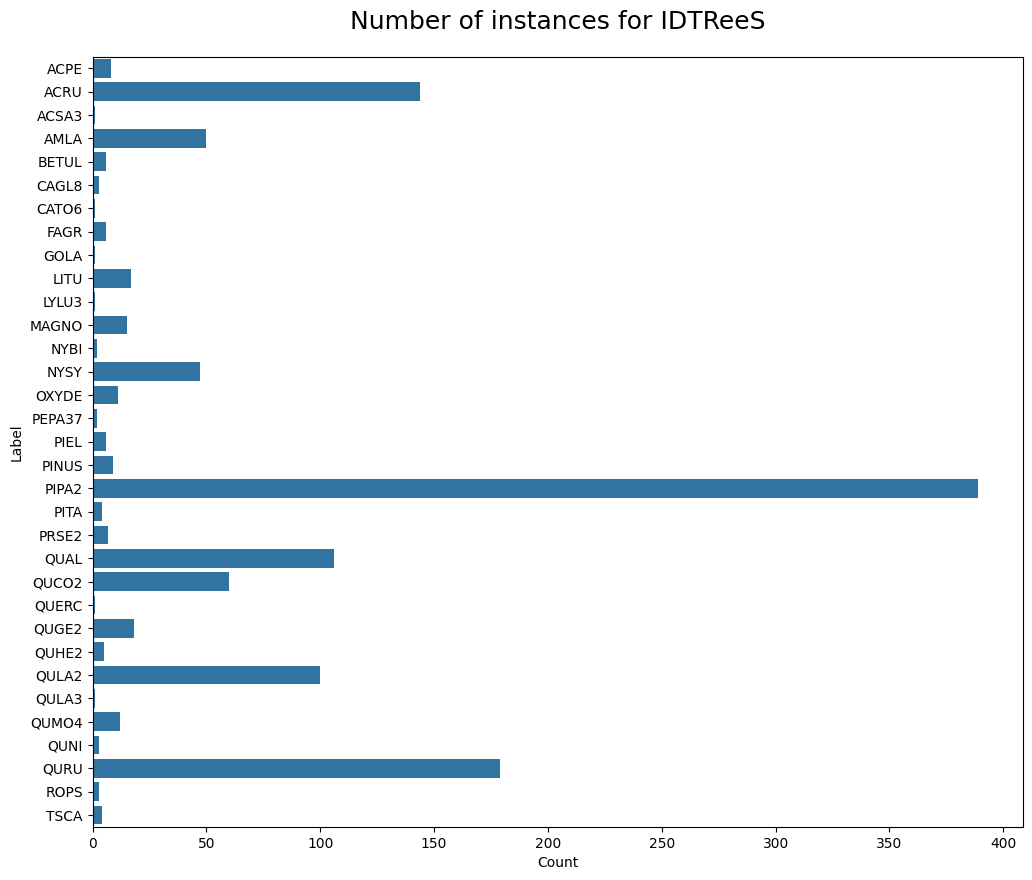

In [80]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 5,
    "shuffle": True,
    "data_dir": "./data/idtrees/IDTREES_competition_train_v2/train/RemoteSensing/RGB/",
    "annotation_dir": "./data/idtrees/IDTREES_competition_train_v2/train/ITC/",
    "csv_file": "./data/idtrees/IDTREES_competition_train_v2/train/Field/train_data.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = IDTReeSDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 85


## Create the model

In [ ]:
epochs = 20
model_directory = "./data/experiments/IDTReeS/"
model_config = {
    "num_classes": 33,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [19]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-10-08 07:55:32,487 INFO Starting training.
training: 100%|██████████| 17/17 [00:04<00:00,  3.83it/s]
2025-10-08 07:55:36,998 INFO epoch: 1, time: 4, loss:  2.68443
testing on train set: 100%|██████████| 17/17 [00:02<00:00,  6.39it/s]
2025-10-08 07:55:42,408 INFO map:0.00020227320783305913, map_50:0.0009309304878115654, map_75:0.00011720917245838791, map_small:0.0, map_medium:0.0002352846204303205, map_large:0.0004110569425392896, mar_1:0.00010437710443511605, mar_10:0.0009812009520828724, mar_100:0.002194724977016449, mar_small:0.0, mar_medium:0.002315096789970994, mar_large:0.0037414967082440853, map_per_class:tensor(0.), tensor(0.0010), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.0057), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0

## Predictions

2025-10-08 08:30:34,909 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/IDTReeS/checkpoint.pth.tar
2025-10-08 08:30:35,240 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/IDTReeS/checkpoint.pth.tar at epoch 21


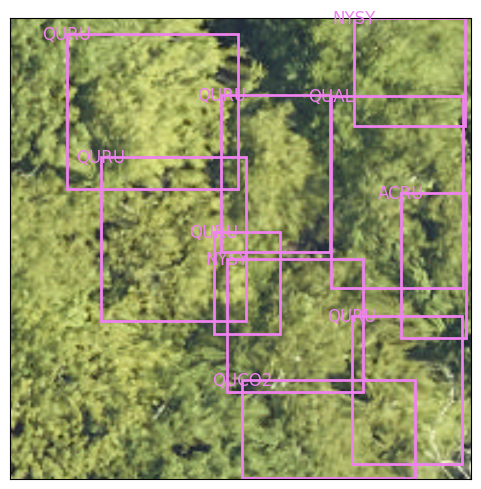

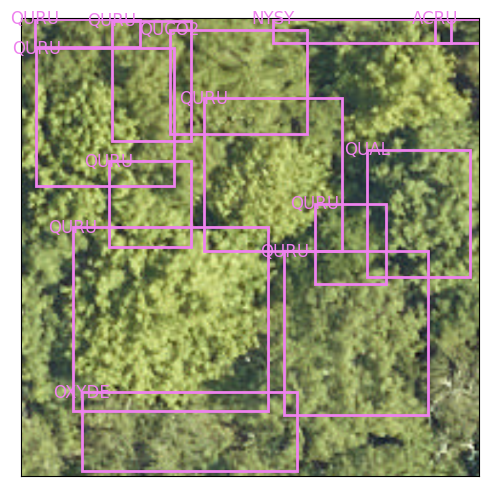

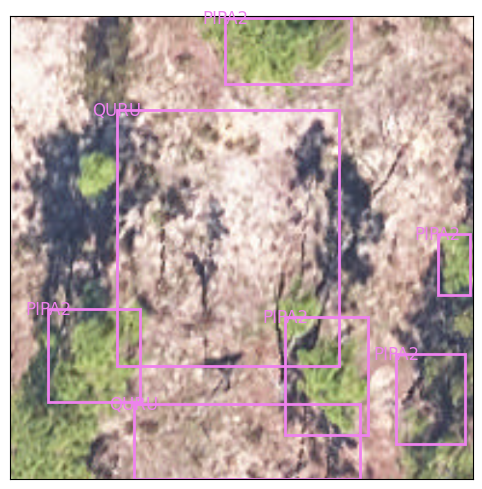

In [ ]:
model_config = {
    "num_classes": 33,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/experiments/IDTReeS/checkpoint.pth.tar"
labels = ["ACPE","ACRU","ACSA3","AMLA","BETUL","CAGL8","CATO6","FAGR","GOLA","LITU","LYLU3","MAGNO","NYBI","NYSY","OXYDE",
        "PEPA37","PIEL","PIPA2","PINUS","PITA","PRSE2","QUAL","QUCO2","QUGE2","QUHE2","QULA2","QULA3","QUMO4","QUNI","QURU",
        "QUERC","ROPS","TSCA"]
transform = Resize()
model.load_model(model_path)

image = image_loader('./data/idtrees/IDTREES_competition_test_v2/task2/RemoteSensing/RGB/MLBS_3.tif')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/idtrees/IDTREES_competition_test_v2/task2/RemoteSensing/RGB/MLBS_47.tif')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/idtrees/IDTREES_competition_test_v2/task2/RemoteSensing/RGB/OSBS_57.tif')
fig = model.detect_objects(image, labels, transform)